In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from scipy.sparse import load_npz
from scipy.stats import loguniform

from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold

In [16]:
X_train = load_npz(
    "processed_data/X_train_processed.npz"
)

y_train = pd.read_csv(
    "processed_data/y_train.csv"
).squeeze()

X_val = load_npz(
    "processed_data/X_val_processed.npz"
)

y_val = pd.read_csv(
    "processed_data/y_val.csv"
).squeeze()

In [17]:
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=150000,
    random_state=42,
    stratify=y_train
)

In [18]:
pipeline = Pipeline([
    ("smote", SMOTE(
        sampling_strategy=0.1,
        random_state=42,
        k_neighbors=5
    )),

    ("sgd", SGDClassifier(
        loss="log_loss",
        max_iter=1000,
        tol=0.001,
        random_state=42
    ))
])

In [19]:
param_grid = {
    "sgd__alpha": loguniform(1e-6, 1e-3),
    "sgd__penalty": ["l1", "l2", "elasticnet"],
    "sgd__l1_ratio": [0.05, 0.15, 0.30, 0.50]
}

In [20]:
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_grid,
    n_iter=10,
    scoring="average_precision",
    cv=cv_strategy,
    random_state=42,
    n_jobs=1,
    verbose=1
)

random_search.fit(X_tune, y_tune)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Parameters:
{'sgd__alpha': np.float64(0.000157029708840554), 'sgd__l1_ratio': 0.05, 'sgd__penalty': 'l1'}

Best Cross-Validation PR-AUC:
0.20222707356548783


In [25]:
tuning_results = pd.DataFrame(random_search.cv_results_)

tuning_results = tuning_results[
    [
        "param_sgd__alpha",
        "param_sgd__penalty",
        "param_sgd__l1_ratio",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].sort_values("rank_test_score")

tuning_results = tuning_results.rename(columns={
    "param_sgd__alpha": "Alpha",
    "param_sgd__penalty": "Penalty",
    "param_sgd__l1_ratio": "L1 Ratio",
    "mean_test_score": "Mean PR-AUC",
    "std_test_score": "Std PR-AUC",
    "rank_test_score": "Rank"
})

display(tuning_results.round(5))



,Alpha,Penalty,L1 Ratio,Mean PR-AUC,Std PR-AUC,Rank
1,0.00016,l1,0.05,0.20223,0.02579,1
4,0.00006,elasticnet,0.50,0.18369,0.02466,2
7,0.00007,l2,0.15,0.18325,0.02503,3
9,0.00004,l2,0.30,0.16463,0.03580,4
2,0.00000,elasticnet,0.30,0.13307,0.03006,5
0,0.00001,elasticnet,0.05,0.13253,0.00653,6
5,0.00000,l2,0.15,0.11473,0.03201,7
8,0.00000,l1,0.05,0.11192,0.02854,8
3,0.00000,l1,0.50,0.10619,0.02180,9
6,0.00000,l1,0.50,0.10590,0.02836,10


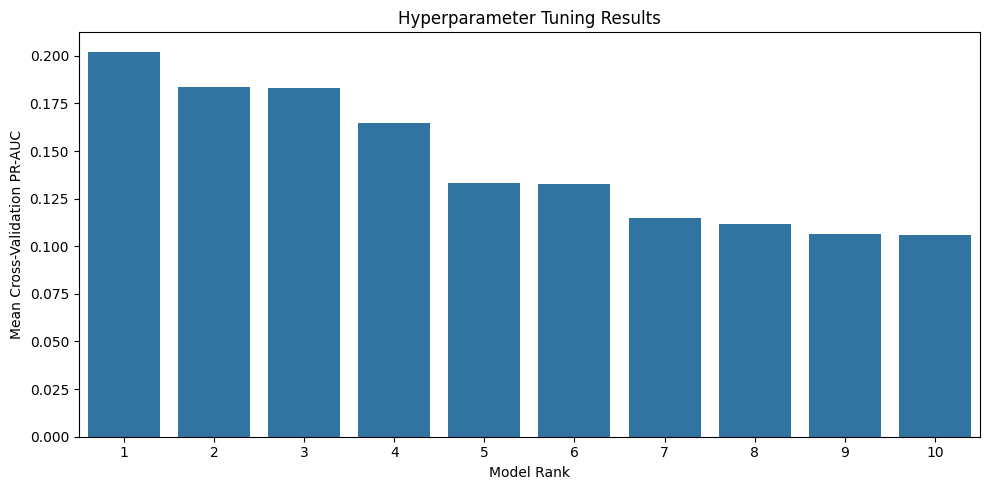

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tuning_results,
    x="Rank",
    y="Mean PR-AUC"
)

plt.title("Hyperparameter Tuning Results")
plt.xlabel("Model Rank")
plt.ylabel("Mean Cross-Validation PR-AUC")

plt.tight_layout()
plt.show()

In [34]:
best_params = random_search.best_params_

tuned_model = Pipeline([
    ("smote", SMOTE(
        sampling_strategy=0.1,
        random_state=42,
        k_neighbors=5
    )),

    ("sgd", SGDClassifier(
        loss="log_loss",
        max_iter=1000,
        tol=0.001,
        random_state=42
    ))
])

tuned_model.set_params(**best_params)

# Train on the complete original training dataset
tuned_model.fit(X_train, y_train)

print("Tuned model trained successfully!")

Tuned model trained successfully!


In [29]:
y_val_pred = tuned_model.predict(X_val)

y_val_prob = tuned_model.predict_proba(X_val)[:, 1]

precision = precision_score(
    y_val, y_val_pred, zero_division=0
)

recall = recall_score(
    y_val, y_val_pred, zero_division=0
)

f1 = f1_score(
    y_val, y_val_pred, zero_division=0
)

roc_auc = roc_auc_score(y_val, y_val_prob)

pr_auc = average_precision_score(y_val, y_val_prob)

print("Tuned Model Validation Results")
print("--------------------------------")

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))

Tuned Model Validation Results
--------------------------------
Precision: 0.3528
Recall: 0.4957
F1 Score: 0.4122
ROC-AUC: 0.8873
PR-AUC: 0.243


In [30]:
comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "PR-AUC"
    ],

    "Baseline Model": [
        0.3753,
        0.5416,
        0.4434,
        np.nan,
        0.2472
    ],

    "Tuned Model": [
        precision,
        recall,
        f1,
        roc_auc,
        pr_auc
    ]
})

display(comparison.round(4))

,Metric,Baseline Model,Tuned Model
0,Precision,0.3753,0.3528
1,Recall,0.5416,0.4957
2,F1 Score,0.4434,0.4122
3,ROC-AUC,NaN,0.8873
4,PR-AUC,0.2472,0.2430


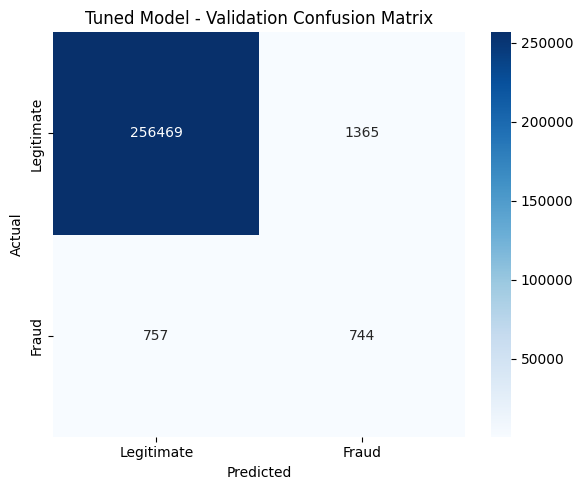

In [31]:
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Tuned Model - Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

In [32]:
print(
    classification_report(
        y_val,
        y_val_pred,
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate       1.00      0.99      1.00    257834
       Fraud       0.35      0.50      0.41      1501

    accuracy                           0.99    259335
   macro avg       0.67      0.75      0.70    259335
weighted avg       0.99      0.99      0.99    259335



In [33]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../reports", exist_ok=True)

# Save tuned model
joblib.dump(
    tuned_model,
    "../models/tuned_sgd_model.pkl"
)

# Save best parameters
joblib.dump(
    best_params,
    "../models/tuned_sgd_parameters.pkl"
)

# Save tuning results
tuning_results.to_csv(
    "../reports/hyperparameter_tuning_results.csv",
    index=False
)

print("Tuned model and results saved successfully!")

Tuned model and results saved successfully!


Observation

Hyperparameter tuning was performed using RandomizedSearchCV with Average Precision as the optimization metric. SMOTE was applied within each cross-validation training fold to prevent data leakage.

The tuned SGD Classifier achieved a validation PR-AUC of 0.2430, compared with 0.2472 for the baseline model. The tuned model also showed lower precision, recall and F1-score.

Therefore, hyperparameter tuning did not produce an improvement over the baseline configuration. The baseline SMOTE-based SGD Classifier was retained as the better-performing model based on the validation results.